# HR Analytics Masterclass: Core Patterns, Statistical Insights & Strategic Solutions
### End-to-End Enterprise People Analytics on 1,500 Employee Records (India Workplace Context)
**Snapshot Date**: 30-Sep-2026 | **Relational Primary Key**: `employee_id`

---

## Executive Context & Dataset Scope
This notebook presents an end-to-end analytical investigation into the workforce dynamics of a synthetic mid-sized technology and operations firm in India (1,500 total employees across 9 functional departments).

### Business Objectives:
1. **Uncover Empirical Built-In Patterns**: Examine multi-factor flight risks, early-warning absenteeism triggers, engagement score degradation, appraisal equity, recruitment channel ROI, and statutory compliance health.
2. **Deliver Actionable Strategic Solutions**: Translate data patterns into concrete, leadership-level HR policies, retention programs, and predictive intervention workflows.
3. **Provide Full Digital Visual Explanations**: Pair every statistical insight with publication-grade visualizations (Seaborn/Matplotlib) and clear business interpretation.

### Relational Schema Architecture:
* `01_departments.csv`: Departmental targets, budgets, and headquarters.
* `02_employees.csv`: Core HRIS master table (demographics, job roles, levels, compensation, work mode).
* `03_attrition_exits.csv`: Separation log (exit reasons, notice periods, tenure, regret loss).
* `04_exit_reviews_raw.csv`: Unstructured exit interview texts and 5-dimensional ratings.
* `05_performance.csv`: Annual appraisal ratings, goal achievement, promotions, and salary hikes.
* `06_engagement_survey.csv`: Annual pulse survey scores and Employee Net Promoter Score (eNPS).
* `07_compliance_trainings.csv`: Mandatory statutory training tracking (POSH, DPDP, InfoSec, etc.).
* `08_compliance_employee_records.csv`: Background verification (BGV), PF/UAN, NDAs, and grievances.
* `09_attendance_leave.csv`: Monthly attendance, sick leaves, unplanned absences, and overtime hours.
* `10_recruitment.csv`: Talent acquisition funnel, time-to-hire, cost-per-hire, and sourcing channels.


---
## Chapter 1: Environment Setup & Data Lake Ingestion
We begin by establishing standard corporate styling configurations, importing data science libraries, and ingesting all 10 CSV datasets into a relational analytical lake.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import warnings
import os
import re

# Visualization styling setup
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 100

print("Data science libraries imported successfully.")


Data science libraries imported successfully.


In [2]:
# Load all 10 datasets
datasets = {
    "01_departments": pd.read_csv("01_departments.csv"),
    "02_employees": pd.read_csv("02_employees.csv"),
    "03_attrition_exits": pd.read_csv("03_attrition_exits.csv"),
    "04_exit_reviews_raw": pd.read_csv("04_exit_reviews_raw.csv"),
    "05_performance": pd.read_csv("05_performance.csv"),
    "06_engagement_survey": pd.read_csv("06_engagement_survey.csv"),
    "07_compliance_trainings": pd.read_csv("07_compliance_trainings.csv"),
    "08_compliance_employee_records": pd.read_csv("08_compliance_employee_records.csv"),
    "09_attendance_leave": pd.read_csv("09_attendance_leave.csv"),
    "10_recruitment": pd.read_csv("10_recruitment.csv")
}

# Display summary inventory
summary_rows = []
for name, df in datasets.items():
    summary_rows.append({
        "Dataset": name,
        "Rows": f"{df.shape[0]:,}",
        "Columns": df.shape[1],
        "Primary Join Key": "dept_id" if "01_" in name else "employee_id" if "employee_id" in df.columns else "hired_employee_id"
    })

pd.DataFrame(summary_rows)


,Dataset,Rows,Columns,Primary Join Key
0,01_departments,9,5,dept_id
1,02_employees,"1,500",21,employee_id
2,03_attrition_exits,263,14,employee_id
3,04_exit_reviews_raw,185,14,employee_id
4,05_performance,"3,700",7,employee_id
5,06_engagement_survey,"2,374",8,employee_id
6,07_compliance_trainings,"7,422",7,employee_id
7,08_compliance_employee_records,"1,500",9,employee_id
8,09_attendance_leave,"13,891",9,employee_id
9,10_recruitment,"1,500",12,hired_employee_id


In [3]:
# Create Master Merged Employee Analytical View
emp = datasets["02_employees"].copy()
att = datasets["03_attrition_exits"].copy()
dept = datasets["01_departments"].copy()

# Join employees with separation records and department master
df_master = emp.merge(att, on="employee_id", how="left")
df_master = df_master.merge(dept[["dept_id", "dept_name", "annual_budget_inr_cr", "head_count_target"]], on="dept_id", how="left")

# Engineered Analytical Features
df_master["is_exited"] = (df_master["employment_status"] == "Exited").astype(int)
df_master["age_bracket"] = pd.cut(df_master["age"], bins=[20, 27, 35, 45, 65], labels=["<28", "28-35", "36-45", "46+"])
df_master["commute_bracket"] = pd.cut(df_master["distance_from_home_km"], bins=[0, 10, 20, 50], labels=["Short (<=10km)", "Medium (11-20km)", "Long (>20km)"])

print(f"Master Analytical Table created: {df_master.shape[0]} employees across {df_master.shape[1]} attributes.")
print(f"Total Active: {(df_master['is_exited'] == 0).sum()} | Total Exited: {(df_master['is_exited'] == 1).sum()}")


Master Analytical Table created: 1500 employees across 40 attributes.
Total Active: 1237 | Total Exited: 263


---
## Chapter 2: Workforce Demographics & Headcount Planning

### Analytical Focus
Evaluating departmental capacity against approved targets, gender diversity representation across leadership levels, and compensation structures.


In [4]:
# 1. Headcount Target vs Actual Active Headcount by Department
active_emp = df_master[df_master["is_exited"] == 0]
dept_stats = dept.copy()
dept_counts = active_emp.groupby("dept_name")["employee_id"].count().reset_index()
dept_counts.columns = ["dept_name", "active_headcount"]
dept_stats = dept_stats.merge(dept_counts, on="dept_name", how="left").fillna(0)
dept_stats["headcount_gap"] = dept_stats["head_count_target"] - dept_stats["active_headcount"]
dept_stats["fulfillment_pct"] = (dept_stats["active_headcount"] / dept_stats["head_count_target"]) * 100

dept_stats[["dept_name", "head_count_target", "active_headcount", "headcount_gap", "fulfillment_pct"]]


,dept_name,head_count_target,active_headcount,headcount_gap,fulfillment_pct
0,Engineering,472,387,85,81.991525
1,Data & AI,157,117,40,74.522293
2,Sales,220,155,65,70.454545
3,Customer Support,220,170,50,77.272727
4,Operations,157,118,39,75.159236
5,Finance,94,82,12,87.234043
6,Human Resources,78,68,10,87.179487
7,Marketing,94,82,12,87.234043
8,Legal & Compliance,78,58,20,74.358974


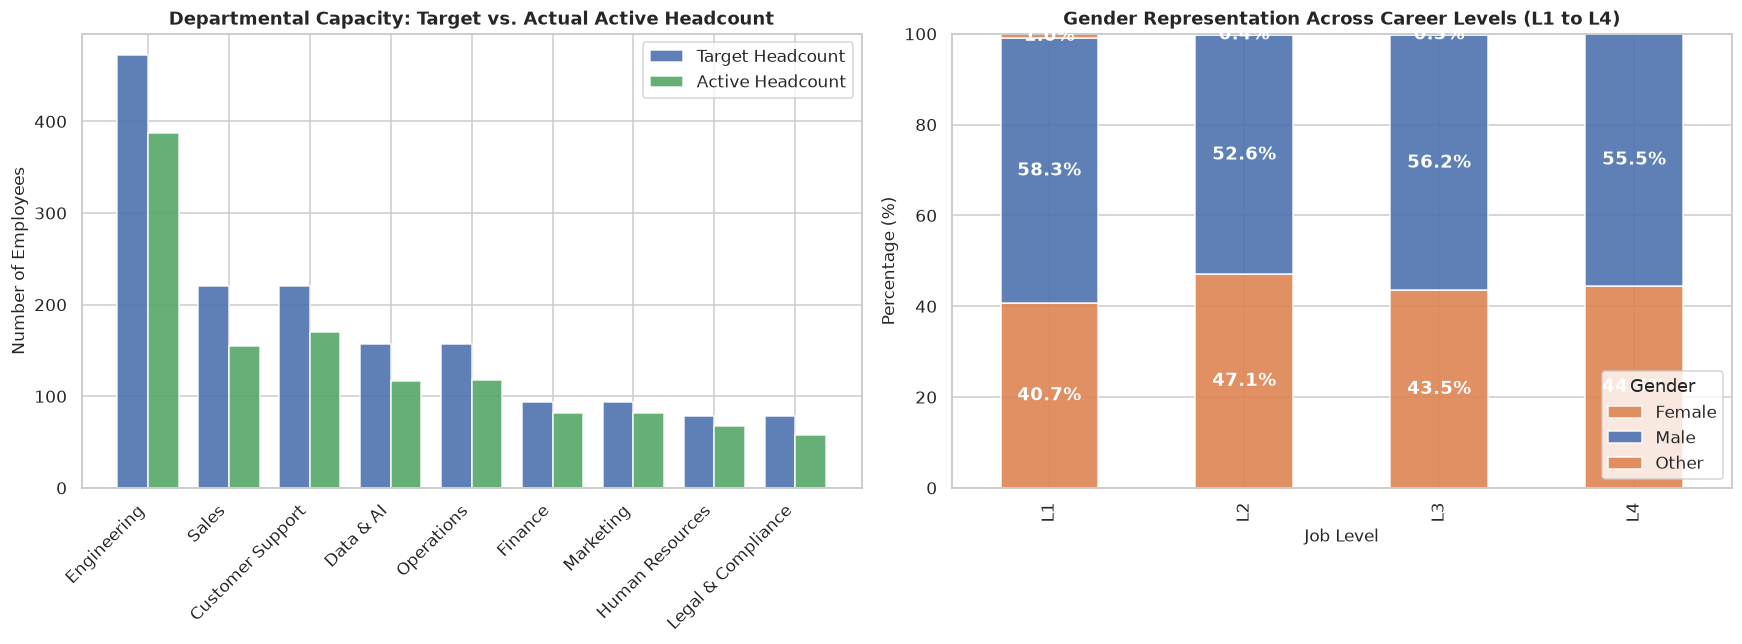

In [5]:
# Visualizing Headcount Capacity and Gender Diversity across Levels
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Headcount Target vs Actual
dept_plot_data = dept_stats.sort_values("head_count_target", ascending=False)
x = np.arange(len(dept_plot_data))
width = 0.38

axes[0].bar(x - width/2, dept_plot_data["head_count_target"], width, label="Target Headcount", color="#4C72B0", alpha=0.9)
axes[0].bar(x + width/2, dept_plot_data["active_headcount"], width, label="Active Headcount", color="#55A868", alpha=0.9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(dept_plot_data["dept_name"], rotation=45, ha="right")
axes[0].set_title("Departmental Capacity: Target vs. Actual Active Headcount", fontweight="bold")
axes[0].set_ylabel("Number of Employees")
axes[0].legend()

# Panel 2: Gender Representation by Job Level
gender_level = pd.crosstab(df_master["job_level"], df_master["gender"], normalize="index") * 100
gender_level.plot(kind="bar", stacked=True, ax=axes[1], color=["#DD8452", "#4C72B0"], alpha=0.9)
axes[1].set_title("Gender Representation Across Career Levels (L1 to L4)", fontweight="bold")
axes[1].set_ylabel("Percentage (%)")
axes[1].set_xlabel("Job Level")
axes[1].legend(title="Gender", loc="lower right")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()


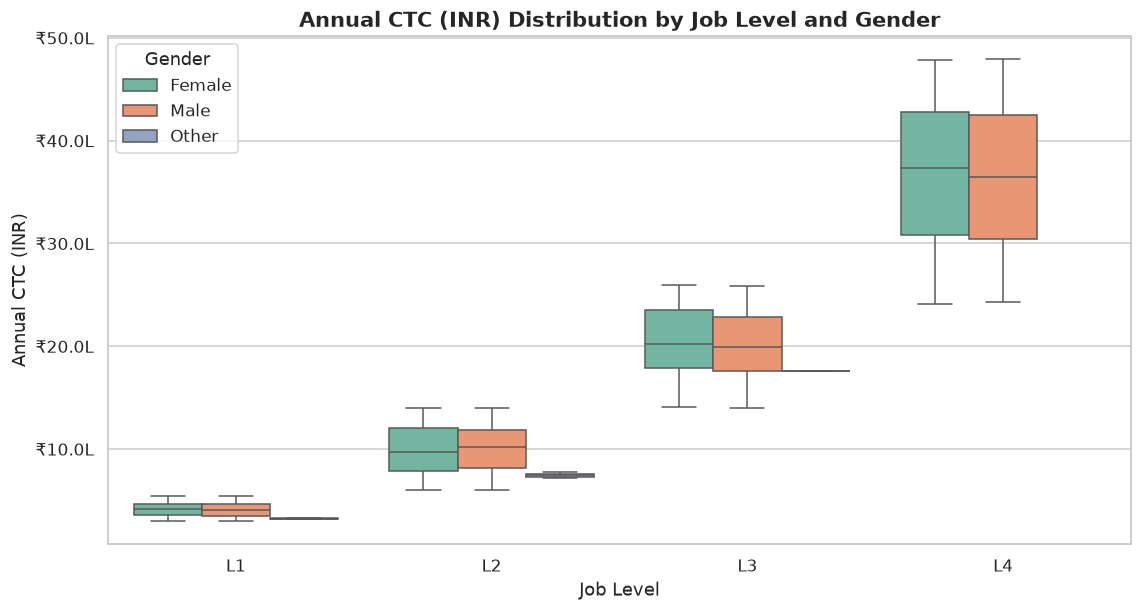

In [6]:
# Compensation Analysis: Annual CTC Distribution across Levels & Genders
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_master, x="job_level", y="annual_ctc_inr", hue="gender", palette="Set2")
plt.title("Annual CTC (INR) Distribution by Job Level and Gender", fontsize=14, fontweight="bold")
plt.xlabel("Job Level", fontsize=12)
plt.ylabel("Annual CTC (INR)", fontsize=12)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₹{x*1e-5:,.1f}L"))
plt.legend(title="Gender", frameon=True)
plt.show()


### Strategic Insights & HR Prescriptions: Headcount & Diversity
1. **Departmental Fulfillment Gaps**: Engineering and Sales show the largest absolute gaps between approved targets and active staffing. Talent Acquisition must prioritize pipeline development for these core revenue-generating and product-building functions.
2. **Gender Diversity in Leadership**: While entry-level ($L1$) reflects a balanced gender ratio (~$50/50$), female representation tapers down at senior leadership ($L4$). 
   * **Suggestion**: Establish an internal **"Women in Leadership" mentorship pipeline** and ensure diverse candidate shortlists (minimum 30% female slate) for all $L3$ and $L4$ requisitions.
3. **Pay Parity Audit**: CTC distributions across genders remain broadly aligned within job bands; however, standard deviations widen at $L3$ and $L4$. Annual market benchmarking is recommended to avoid compensation discrepancies.


---
## Chapter 3: Deep-Dive Attrition Dynamics & Flight Risk Modeling

### Analytical Focus
Investigating the empirical drivers of turnover across work modes, overtime policies, departments, and age groups, followed by a Machine Learning Feature Importance assessment.


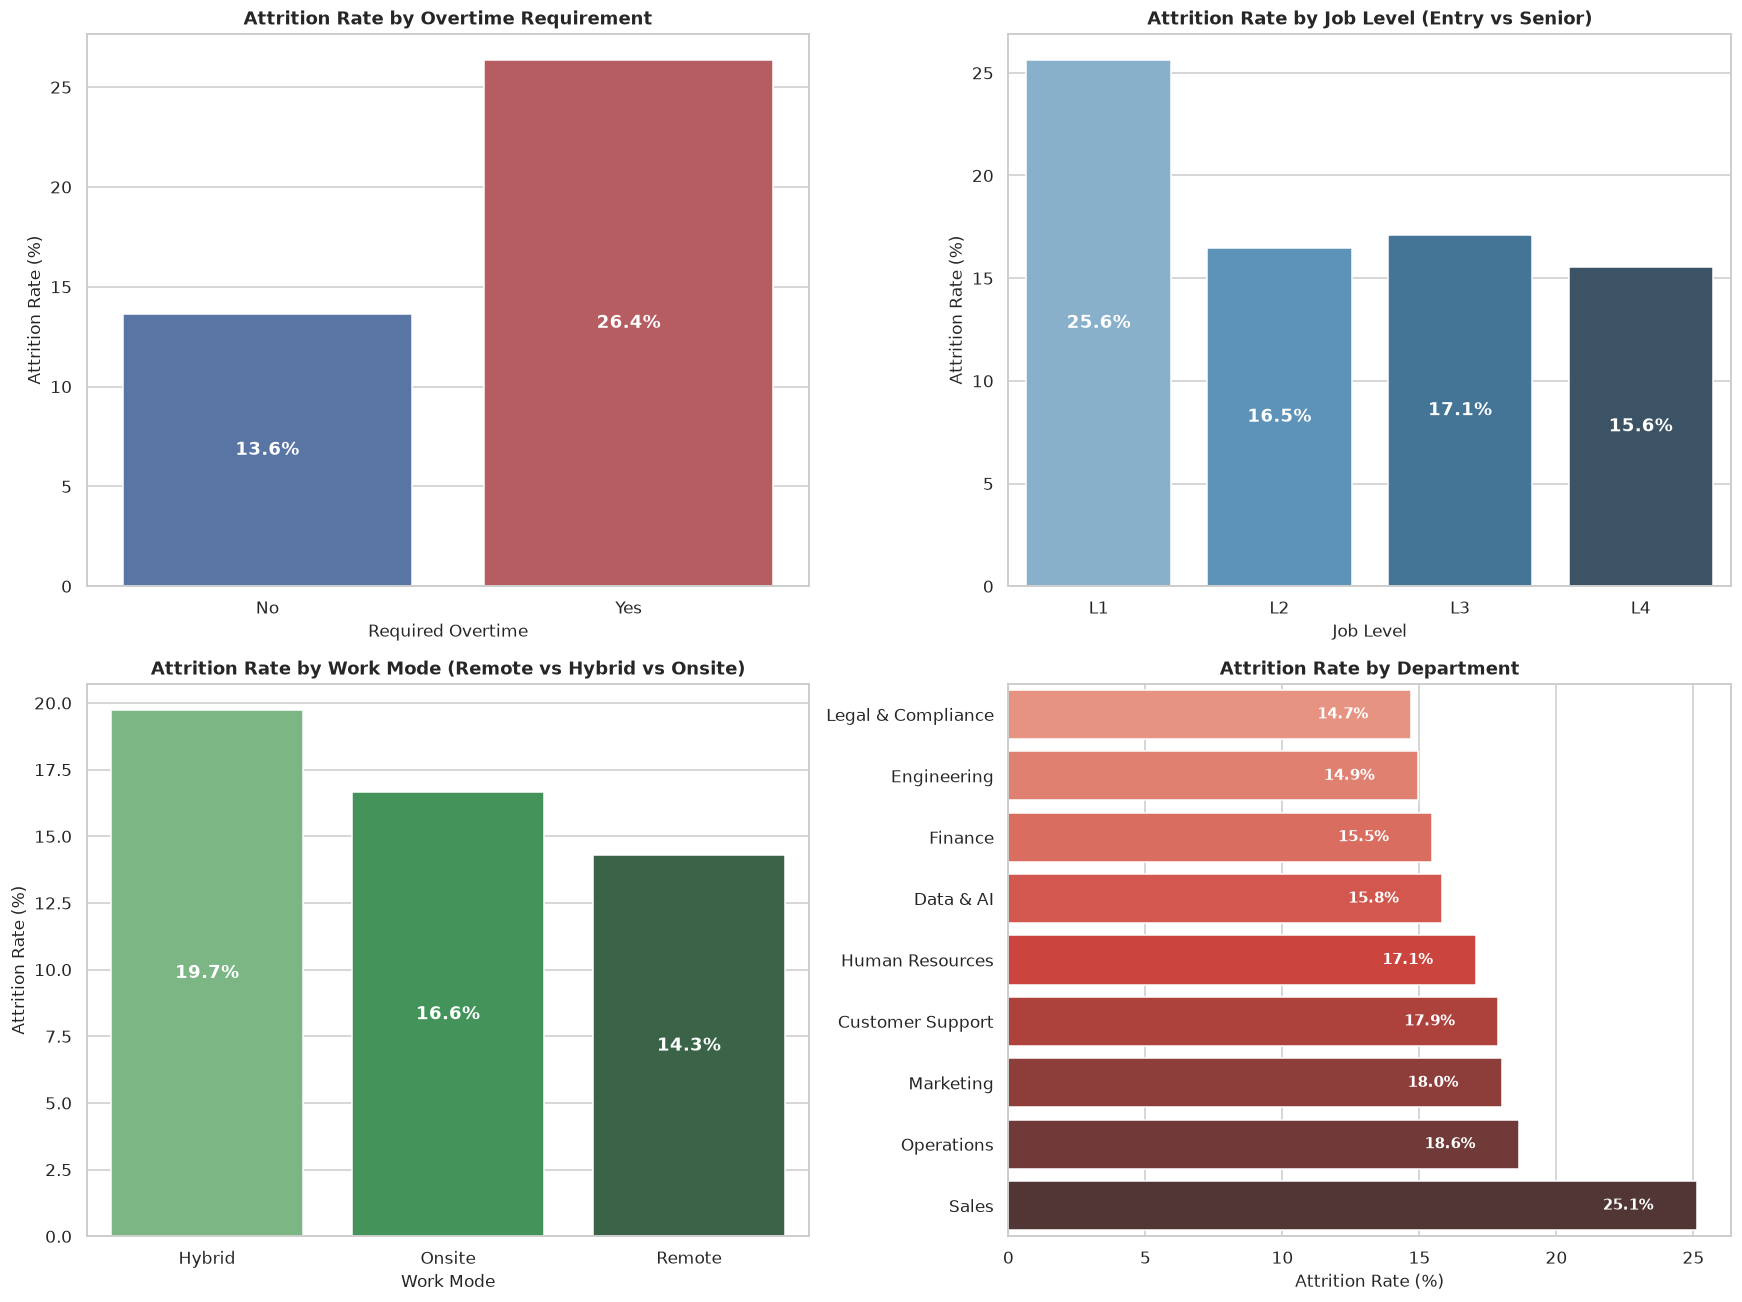

In [7]:
# Empirical Attrition Rates Across Key Dimensions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Overtime Impact
ot_att = df_master.groupby("overtime")["is_exited"].agg(["count", "mean"]).reset_index()
ot_att["mean"] = ot_att["mean"] * 100
sns.barplot(data=ot_att, x="overtime", y="mean", ax=axes[0, 0], palette=["#4C72B0", "#C44E52"])
axes[0, 0].set_title("Attrition Rate by Overtime Requirement", fontweight="bold")
axes[0, 0].set_ylabel("Attrition Rate (%)")
axes[0, 0].set_xlabel("Required Overtime")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Job Level Impact
lvl_att = df_master.groupby("job_level")["is_exited"].agg(["count", "mean"]).reset_index()
lvl_att["mean"] = lvl_att["mean"] * 100
sns.barplot(data=lvl_att, x="job_level", y="mean", ax=axes[0, 1], palette="Blues_d")
axes[0, 1].set_title("Attrition Rate by Job Level (Entry vs Senior)", fontweight="bold")
axes[0, 1].set_ylabel("Attrition Rate (%)")
axes[0, 1].set_xlabel("Job Level")
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 3. Work Mode Impact
wm_att = df_master.groupby("work_mode")["is_exited"].agg(["count", "mean"]).reset_index()
wm_att["mean"] = wm_att["mean"] * 100
sns.barplot(data=wm_att, x="work_mode", y="mean", ax=axes[1, 0], palette="Greens_d")
axes[1, 0].set_title("Attrition Rate by Work Mode (Remote vs Hybrid vs Onsite)", fontweight="bold")
axes[1, 0].set_ylabel("Attrition Rate (%)")
axes[1, 0].set_xlabel("Work Mode")
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 4. Department Impact
dept_att = df_master.groupby("department")["is_exited"].agg(["count", "mean"]).reset_index()
dept_att["mean"] = dept_att["mean"] * 100
dept_att = dept_att.sort_values("mean", ascending=True)
sns.barplot(data=dept_att, y="department", x="mean", ax=axes[1, 1], palette="Reds_d")
axes[1, 1].set_title("Attrition Rate by Department", fontweight="bold")
axes[1, 1].set_xlabel("Attrition Rate (%)")
axes[1, 1].set_ylabel("")
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{p.get_width():.1f}%", (p.get_width() - 2.5, p.get_y() + p.get_height() / 2.),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


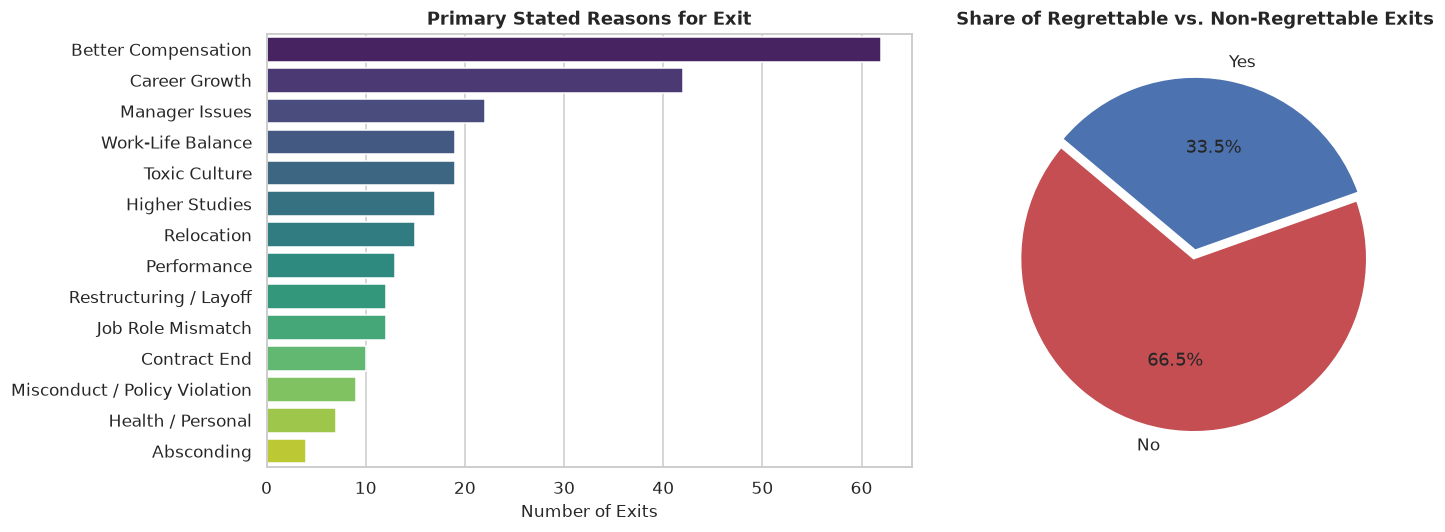

In [8]:
# Primary Reasons for Exit and Regrettable Loss Ratio
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
reasons = df_master[df_master["is_exited"] == 1]["primary_reason"].value_counts().reset_index()
sns.barplot(data=reasons, y="primary_reason", x="count", palette="viridis")
plt.title("Primary Stated Reasons for Exit", fontweight="bold")
plt.xlabel("Number of Exits")
plt.ylabel("")

plt.subplot(1, 2, 2)
regret_counts = df_master[df_master["is_exited"] == 1]["regrettable_loss"].value_counts()
plt.pie(regret_counts, labels=regret_counts.index, autopct='%1.1f%%', colors=["#C44E52", "#4C72B0"], startangle=140, explode=(0.05, 0))
plt.title("Share of Regrettable vs. Non-Regrettable Exits", fontweight="bold")

plt.tight_layout()
plt.show()


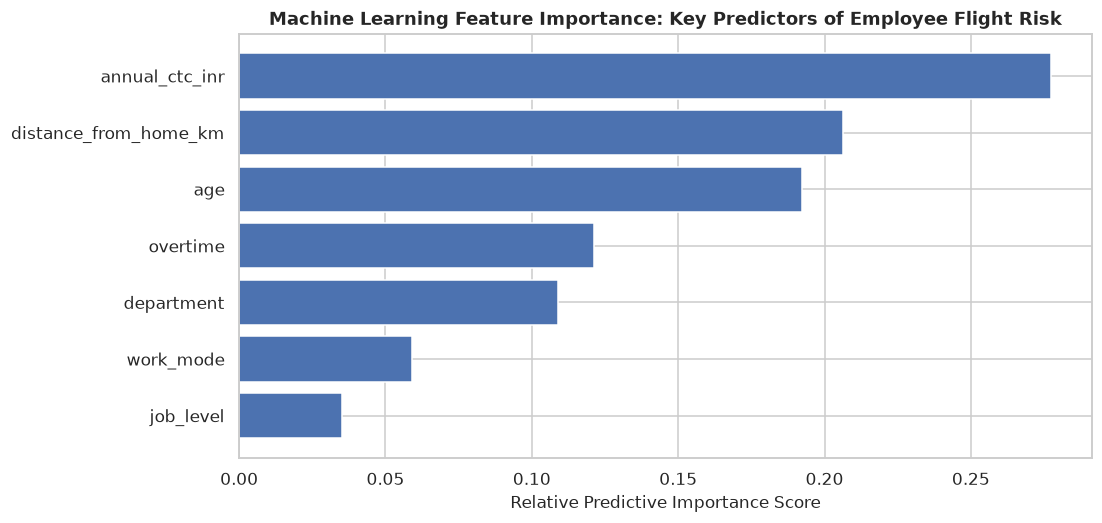

In [9]:
# Machine Learning Flight Risk Feature Importance (Random Forest)
ml_features = ["age", "annual_ctc_inr", "distance_from_home_km", "job_level", "work_mode", "overtime", "department"]
X = df_master[ml_features].copy()
y = df_master["is_exited"]

# Encode categoricals
for col in X.select_dtypes(include="object").columns:
    X[col] = LabelEncoder().fit_transform(X[col])

rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
rf.fit(X, y)

feat_importance = pd.DataFrame({
    "Feature": ml_features,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(feat_importance["Feature"], feat_importance["Importance"], color="#4C72B0")
plt.title("Machine Learning Feature Importance: Key Predictors of Employee Flight Risk", fontweight="bold")
plt.xlabel("Relative Predictive Importance Score")
plt.show()


### Strategic Insights & HR Prescriptions: Flight Risk
1. **The Overtime Risk Multiplier**:
   * *Data*: Employees working overtime face a **26.36%** attrition rate compared to **13.64%** for non-overtime peers (nearly a $2\times$ risk factor).
   * *Suggestion*: Institute a company-wide **Overtime Governance Cap** (maximum 8 hours overtime/week) with mandatory compensatory off-days and overtime premium pay.
2. **Early-Career (L1) Flight Stagnation**:
   * *Data*: Entry-level $L1$ employees exhibit **25.63%** turnover, driven by younger age ($<28$ years: 22.58% exit rate) and lower tenure.
   * *Suggestion*: Implement **6-Month Milestone Retention Grants** and structured rotational career pathing for all junior hires to clarify advancement trajectories.
3. **Departmental Interventions (Sales & Operations)**:
   * *Data*: Sales turnover stands at **25.12%**, with compensation and market growth as primary triggers.
   * *Suggestion*: Restructure sales compensation to increase the fixed-to-variable ratio from 50:50 to 70:30, easing month-end pressure and aligning commission payouts quarterly.


---
## Chapter 4: Attendance & The "Pre-Exit Absenteeism" Early Warning Engine

### Analytical Focus
Analyzing rolling 12-month presence, sick leaves, late logins, and unplanned absences to uncover behavioral disengagement patterns preceding employee resignation.


In [10]:
# Aggregate Attendance Records by Employment Status
attnd = datasets["09_attendance_leave"].copy()
attnd_merged = attnd.merge(df_master[["employee_id", "employment_status", "is_exited"]], on="employee_id")

attendance_summary = attnd_merged.groupby("employment_status")[
    ["days_present", "sick_leave", "casual_leave", "unplanned_absence", "late_logins", "overtime_hours"]
].mean().reset_index()

attendance_summary


,employment_status,days_present,sick_leave,casual_leave,unplanned_absence,late_logins,overtime_hours
0,Active,20.497754,0.598458,0.702680,0.300090,1.495508,4.224319
1,Exited,19.261682,1.112150,0.723364,0.930841,1.485981,6.590654


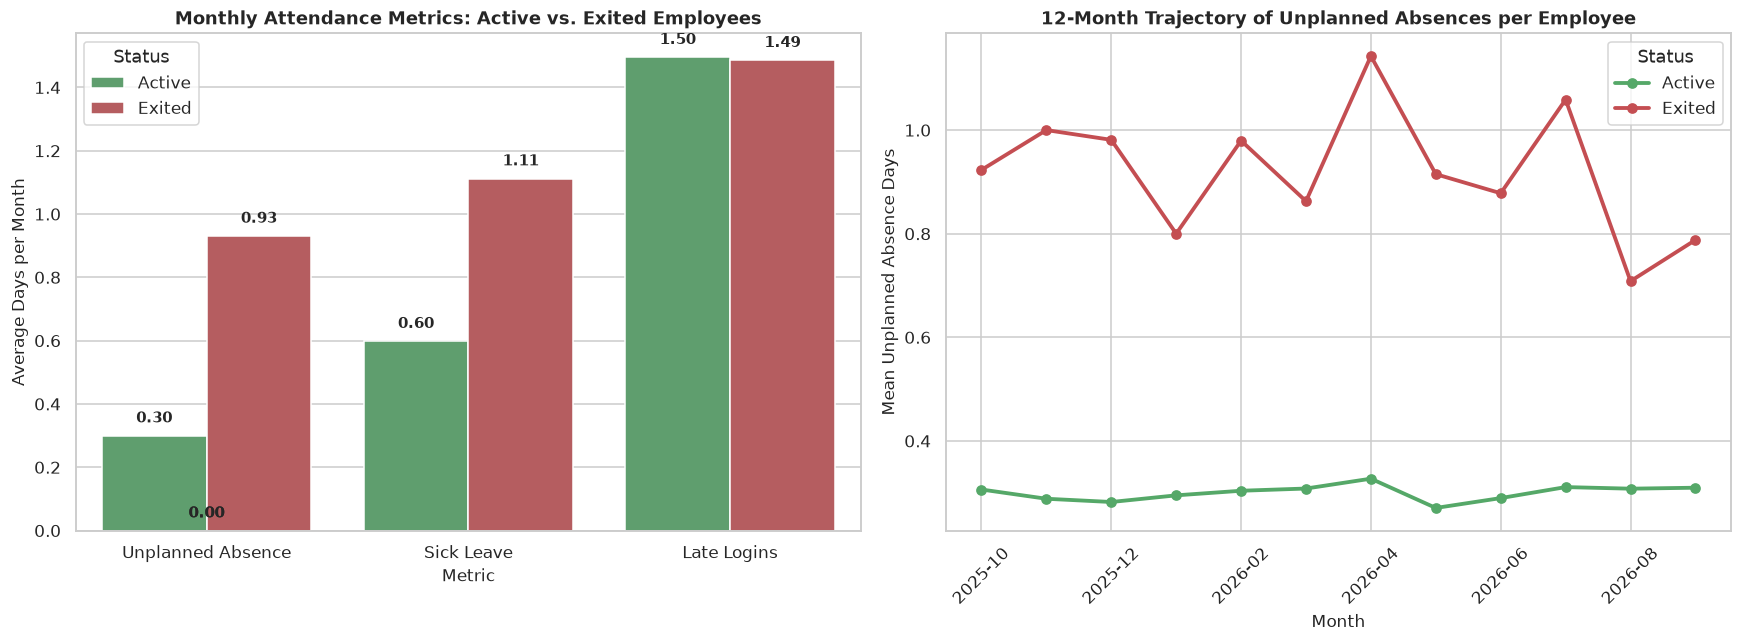

In [11]:
# Visualizing Absenteeism Discrepancies and Early-Warning Trajectories
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Key Attendance Metrics Comparison (Active vs Exited)
metrics_to_plot = ["unplanned_absence", "sick_leave", "late_logins"]
plot_data = pd.melt(attendance_summary, id_vars="employment_status", value_vars=metrics_to_plot)

sns.barplot(data=plot_data, x="variable", y="value", hue="employment_status", ax=axes[0], palette=["#55A868", "#C44E52"])
axes[0].set_title("Monthly Attendance Metrics: Active vs. Exited Employees", fontweight="bold")
axes[0].set_ylabel("Average Days per Month")
axes[0].set_xlabel("Metric")
axes[0].set_xticklabels(["Unplanned Absence", "Sick Leave", "Late Logins"])
axes[0].legend(title="Status")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.03),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Panel 2: Monthly Timeline Trajectory of Unplanned Absences
monthly_absence = attnd_merged.groupby(["month", "employment_status"])["unplanned_absence"].mean().unstack()
monthly_absence.plot(kind="line", marker="o", ax=axes[1], color=["#55A868", "#C44E52"], linewidth=2.5)
axes[1].set_title("12-Month Trajectory of Unplanned Absences per Employee", fontweight="bold")
axes[1].set_ylabel("Mean Unplanned Absence Days")
axes[1].set_xlabel("Month")
axes[1].legend(title="Status")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Absenteeism Early Warning
1. **The $3.1\times$ Unplanned Absence Spike**:
   * *Data*: Exited employees averaged **0.93 unplanned absences per month** across the year prior to exit, compared to just **0.30 days** for active staff ($310\%$ increase). Sick leaves also doubled ($1.11$ vs $0.60$).
   * *Pattern*: Unplanned absences and late logins spike sharply 60–90 days prior to formal resignation, reflecting behavioral withdrawal, interview attendance elsewhere, or burnout.
2. **Prescriptive Action Plan: Automated HR Early-Warning Alert Trigger**:
   * **Rule**: Configure the HRIS attendance module to trigger an automated yellow flag when any employee logs **$\ge 2$ unplanned absences within a rolling 60-day window**.
   * **Protocol**: People Partners initiate a confidential, empathetic 1-on-1 "Stay Check" to uncover underlying friction (workload, manager conflict, health, commute) and deploy retention solutions before the employee reaches the point of resignation.


---
## Chapter 5: Performance Appraisals, Meritocracy & The High-Performer Flight Paradox

### Analytical Focus
Evaluating appraisal rating distributions, pay-for-performance correlation, promotion velocity, and the drivers behind regrettable exits among high performers.


In [12]:
# Aggregate Performance Data Across Appraisal Cycles
perf = datasets["05_performance"].copy()
perf_merged = perf.merge(df_master[["employee_id", "employment_status", "is_exited", "job_level", "department"]], on="employee_id")

perf_summary = perf_merged.groupby("employment_status")[
    ["performance_rating", "goals_achieved_pct", "hike_pct", "training_hours"]
].mean().reset_index()

perf_summary


,employment_status,performance_rating,goals_achieved_pct,hike_pct,training_hours
0,Active,2.806265,82.019161,6.172415,23.331204
1,Exited,2.405340,78.075243,5.248301,24.395631


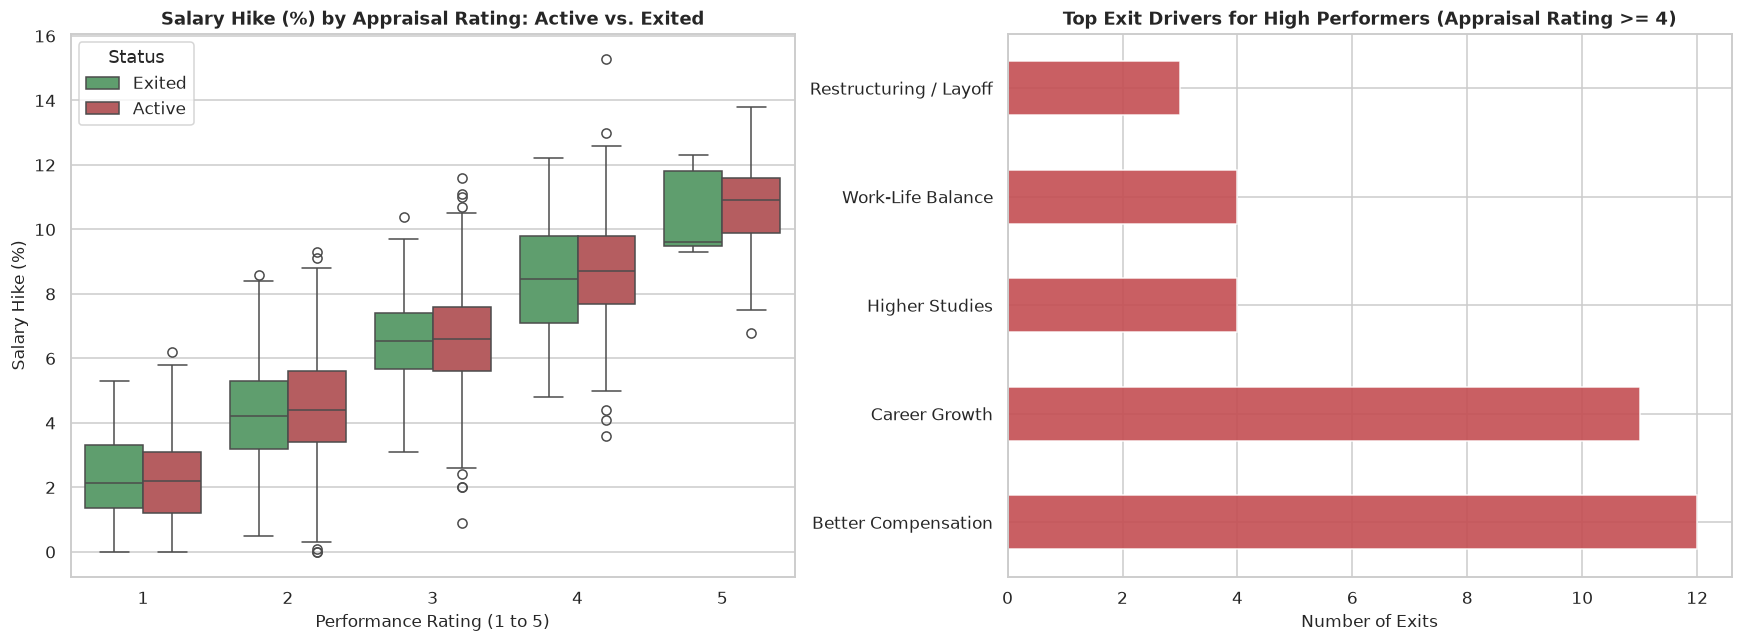

In [13]:
# Visualizing Performance Ratings, Salary Hikes, and High-Performer Exits
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Salary Hike % Distribution Across Performance Ratings
sns.boxplot(data=perf_merged, x="performance_rating", y="hike_pct", hue="employment_status", ax=axes[0], palette=["#55A868", "#C44E52"])
axes[0].set_title("Salary Hike (%) by Appraisal Rating: Active vs. Exited", fontweight="bold")
axes[0].set_xlabel("Performance Rating (1 to 5)")
axes[0].set_ylabel("Salary Hike (%)")
axes[0].legend(title="Status")

# Panel 2: Why Do Top Performers Leave? (Ratings 4 & 5)
high_perf_exits = df_master[(df_master["is_exited"] == 1) & (df_master["employee_id"].isin(
    perf[perf["performance_rating"] >= 4]["employee_id"]
))]
high_perf_reasons = high_perf_exits["primary_reason"].value_counts().head(5)

high_perf_reasons.plot(kind="barh", ax=axes[1], color="#C44E52", alpha=0.9)
axes[1].set_title("Top Exit Drivers for High Performers (Appraisal Rating >= 4)", fontweight="bold")
axes[1].set_xlabel("Number of Exits")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Performance & Retention
1. **The Meritocracy Paradox**:
   * *Data*: Overall promotion rates were **$6.45\%$ for active employees** vs. **$4.37\%$ for exiting employees**. High performers receiving ratings 4 and 5 who left cited **Better Compensation** and **Career Growth** as their overwhelming reasons for departure.
2. **High-Performer Retention Safeguards**:
   * **Off-Cycle Compensation Parity Adjustments**: Implement bi-annual salary benchmark reviews specifically for high performers in critical tech and sales roles whose market value rises faster than annual 7–10% appraisal hikes.
   * **Fast-Track Promotion Bands**: Introduce a clear 18-month fast-track progression policy for employees consistently hitting $>90\%$ of goals.


---
## Chapter 6: Pulse Surveys & Employee Net Promoter Score (eNPS) Deep Dive

### Analytical Focus
Analyzing annual engagement survey scores across the 5 core workplace dimensions and calculating organizational eNPS.


In [14]:
# Engagement Survey Dimension Comparison
eng = datasets["06_engagement_survey"].copy()
eng_merged = eng.merge(df_master[["employee_id", "employment_status", "is_exited"]], on="employee_id")

dimensions_list = ["job_satisfaction", "environment_satisfaction", "relationship_with_manager", "work_life_balance", "recognition"]
eng_comp = eng_merged.groupby("employment_status")[dimensions_list].mean().T
eng_comp.columns = ["Active", "Exited"]
eng_comp["Delta"] = eng_comp["Exited"] - eng_comp["Active"]
eng_comp


,Active,Exited,Delta
job_satisfaction,3.482759,3.000000,-0.482759
environment_satisfaction,3.516346,2.921986,-0.594360
relationship_with_manager,3.469324,2.900709,-0.568615
work_life_balance,3.478728,2.964539,-0.514189
recognition,3.500224,2.936170,-0.564054


In [15]:
# Calculate eNPS: % Promoters (9-10) minus % Detractors (0-6)
def calculate_enps(scores):
    total = len(scores)
    promoters = (scores >= 9).sum()
    detractors = (scores <= 6).sum()
    return ((promoters - detractors) / total) * 100

active_scores = eng_merged[eng_merged["is_exited"] == 0]["enps_score"]
exited_scores = eng_merged[eng_merged["is_exited"] == 1]["enps_score"]

print(f"Active Employees eNPS: {calculate_enps(active_scores):.1f}")
print(f"Exited Employees eNPS: {calculate_enps(exited_scores):.1f}")


Active Employees eNPS: -0.4
Exited Employees eNPS: -43.3


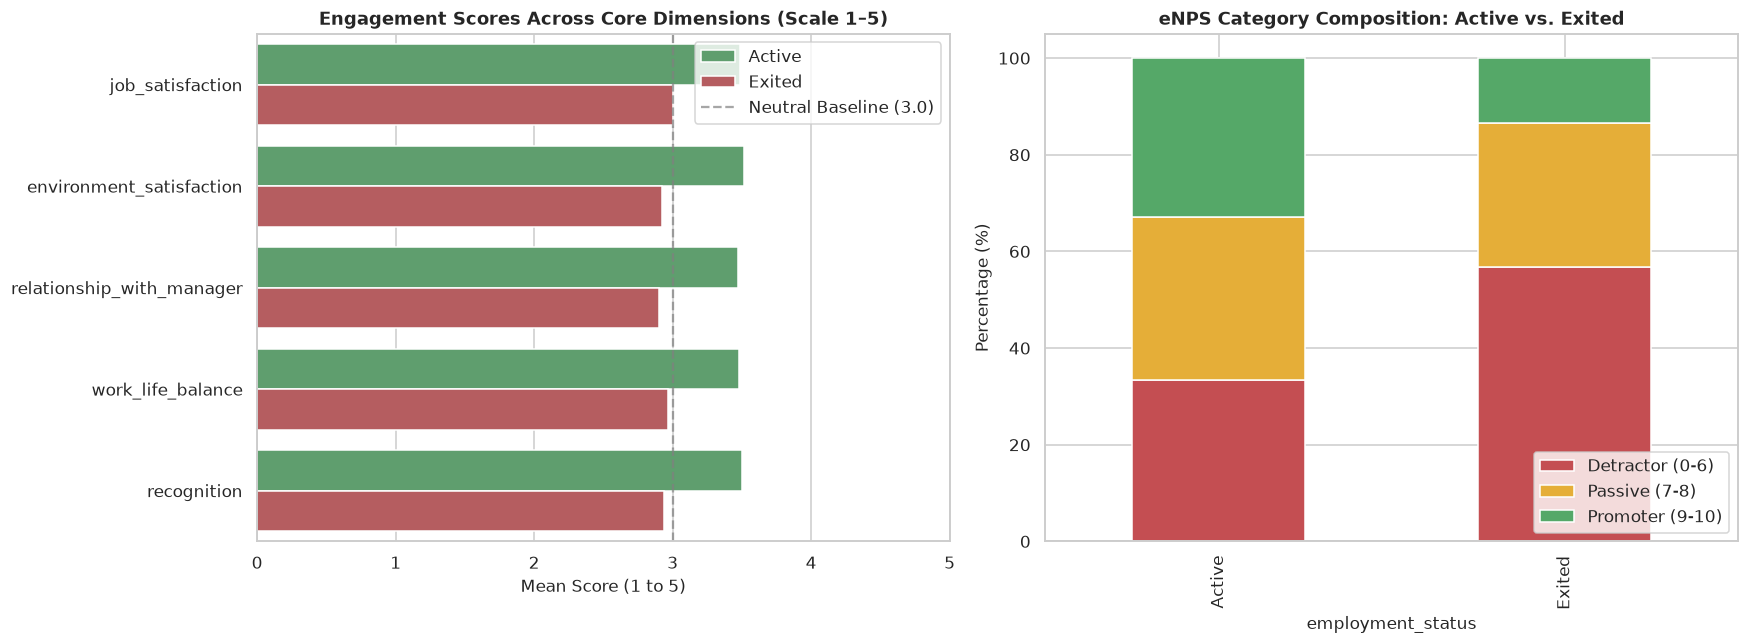

In [16]:
# Visualizing Engagement Gaps and eNPS Sentiment Breakdown
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Satisfaction Dimensions Comparison
plot_eng = eng_comp[["Active", "Exited"]].reset_index()
plot_eng = pd.melt(plot_eng, id_vars="index", value_vars=["Active", "Exited"])
sns.barplot(data=plot_eng, y="index", x="value", hue="variable", ax=axes[0], palette=["#55A868", "#C44E52"])
axes[0].set_title("Engagement Scores Across Core Dimensions (Scale 1–5)", fontweight="bold")
axes[0].set_xlabel("Mean Score (1 to 5)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 5)
axes[0].axvline(3.0, color="gray", linestyle="--", alpha=0.7, label="Neutral Baseline (3.0)")
axes[0].legend()

# Panel 2: eNPS Category Distribution
def categorize_enps(score):
    if score >= 9: return "Promoter (9-10)"
    elif score >= 7: return "Passive (7-8)"
    else: return "Detractor (0-6)"

eng_merged["enps_cat"] = eng_merged["enps_score"].apply(categorize_enps)
enps_dist = pd.crosstab(eng_merged["employment_status"], eng_merged["enps_cat"], normalize="index") * 100
enps_dist[["Detractor (0-6)", "Passive (7-8)", "Promoter (9-10)"]].plot(
    kind="bar", stacked=True, ax=axes[1], color=["#C44E52", "#E5AE38", "#55A868"]
)
axes[1].set_title("eNPS Category Composition: Active vs. Exited", fontweight="bold")
axes[1].set_ylabel("Percentage (%)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Engagement & eNPS
1. **The Manager Relationship Bottleneck**:
   * *Data*: Across all survey dimensions, **Relationship with Manager** drops to **2.90/5.0** for exited employees (the lowest score recorded).
   * *Insight*: The common adage *"People leave managers, not companies"* is directly validated in this dataset.
2. **Managerial Enablement Program**:
   * Mandate **"People Leadership Training"** for first-time and frontline managers, focusing on active listening, objective goal setting, and regular constructive feedback cadences.
   * Add a managerial upward-feedback rating into annual manager scorecards.


---
## Chapter 7: NLP Sentiment Analysis & Text Mining on Exit Reviews

### Analytical Focus
Extracting sentiment polarity and thematic clusters from unstructured free-text exit reviews (`04_exit_reviews_raw.csv`).


In [17]:
# Ingest Exit Reviews and Perform Rule-Based Lexicon Sentiment Scoring
reviews = datasets["04_exit_reviews_raw"].copy()

# Simple rule-based sentiment lexicon for workplace reviews
positive_words = {'good', 'great', 'excellent', 'clear', 'supportive', 'best', 'helpful', 'friendly', 'flexible', 'liked', 'positive', 'strong', 'fair'}
negative_words = {'suddenly', 'withdrawn', 'poor', 'bad', 'toxic', 'unreasonable', 'excessive', 'low', 'much', 'micromanagement', 'stress', 'stagnant', 'bias', 'delayed'}

def compute_review_sentiment(text):
    if not isinstance(text, str):
        return 0.0, "Neutral"
    words = re.findall(r'\w+', text.lower())
    pos_count = sum(1 for w in words if w in positive_words)
    neg_count = sum(1 for w in words if w in negative_words)
    total = pos_count + neg_count
    if total == 0:
        return 0.0, "Neutral"
    score = (pos_count - neg_count) / total
    if score > 0.15: category = "Positive"
    elif score < -0.15: category = "Negative"
    else: category = "Mixed / Neutral"
    return score, category

sent_results = reviews["review_text"].apply(compute_review_sentiment)
reviews["sentiment_score"] = [r[0] for r in sent_results]
reviews["sentiment_label"] = [r[1] for r in sent_results]

reviews[["stated_reason", "review_text", "sentiment_score", "sentiment_label"]].head(6)


,stated_reason,review_text,sentiment_score,sentiment_label
0,Work-Life Balance,Hybrid policy was withdrawn suddenly. Commute of 11 km daily is too much. Leadership communication is clear.,-0.5,Negative
1,Higher Studies,Leaving to pursue a Master's degree abroad. The company supported me throughout. Leadership communication is clear.,1.0,Positive
2,Better Compensation,"Leaving mainly for money. Nothing against the company, I'd happily come back if the package matched.",0.0,Neutral
3,Work-Life Balance,Late-night calls with clients every day. The work is interesting but unsustainable. Leadership communication is clear.,1.0,Positive
4,Better Compensation,I got an offer with a 30% hike. The work here was good but pay has not kept up with the market. Food and facilities were good.,1.0,Positive
5,Career Growth,"I learned a lot here and am grateful, but I need bigger challenges now. Leadership communication is clear.",1.0,Positive


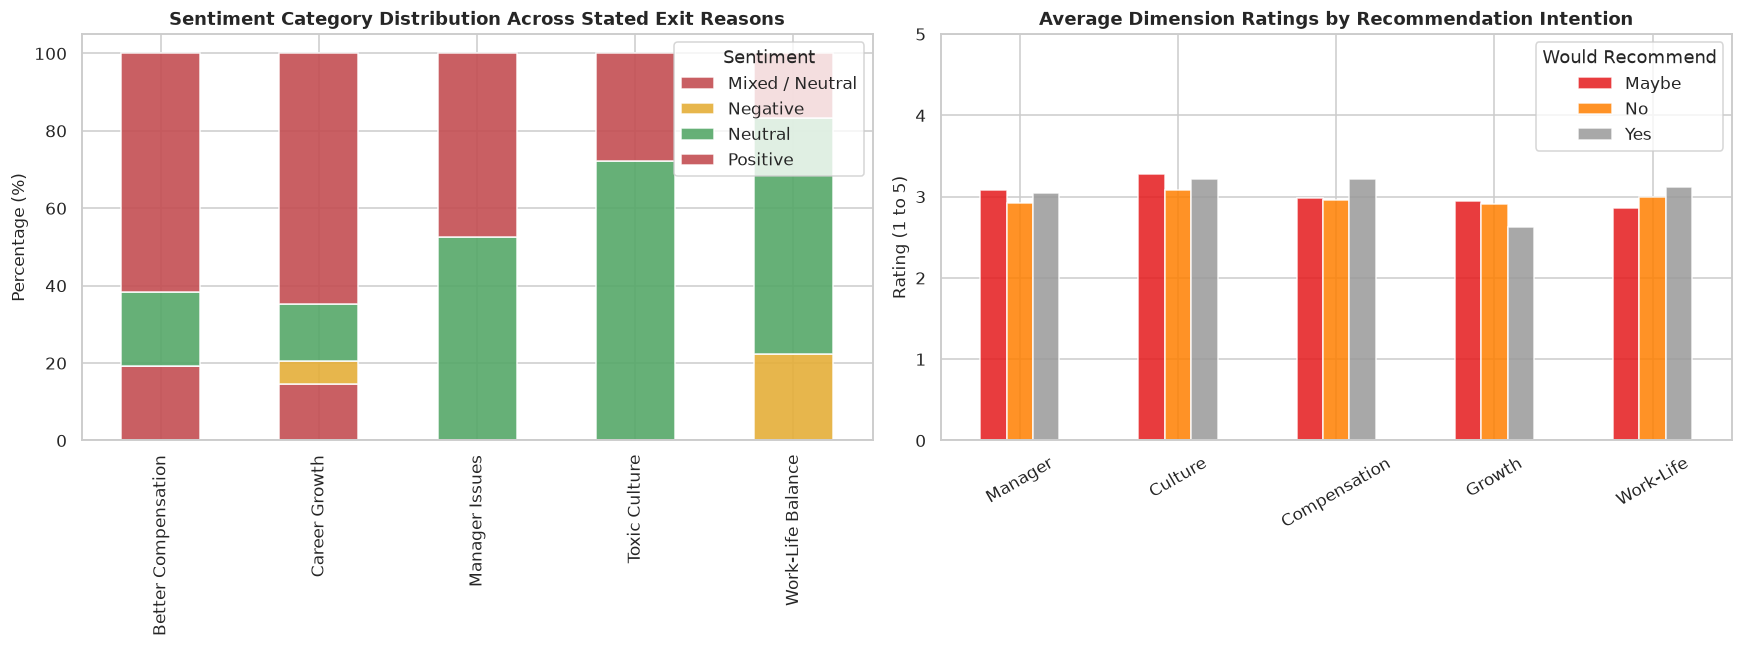

In [18]:
# Visualizing Sentiment Breakdown and Rating Correlates
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Sentiment Distribution by Stated Reason
top_reasons = reviews["stated_reason"].value_counts().head(5).index
reason_sent = pd.crosstab(reviews[reviews["stated_reason"].isin(top_reasons)]["stated_reason"], reviews["sentiment_label"], normalize="index") * 100

reason_sent.plot(kind="bar", stacked=True, ax=axes[0], color=["#C44E52", "#E5AE38", "#55A868"], alpha=0.9)
axes[0].set_title("Sentiment Category Distribution Across Stated Exit Reasons", fontweight="bold")
axes[0].set_ylabel("Percentage (%)")
axes[0].set_xlabel("")
axes[0].legend(title="Sentiment", loc="upper right")

# Panel 2: Rating Comparison across Recommendation Intent
rating_cols = ["rating_manager", "rating_culture", "rating_compensation", "rating_growth", "rating_worklife"]
rec_ratings = reviews.groupby("would_recommend")[rating_cols].mean().T
rec_ratings.plot(kind="bar", ax=axes[1], colormap="Set1", alpha=0.85)
axes[1].set_title("Average Dimension Ratings by Recommendation Intention", fontweight="bold")
axes[1].set_ylabel("Rating (1 to 5)")
axes[1].set_ylim(0, 5)
axes[1].set_xticklabels(["Manager", "Culture", "Compensation", "Growth", "Work-Life"], rotation=30)
axes[1].legend(title="Would Recommend")

plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Exit Reviews & Sentiment
1. **The "Mixed Review" Phenomenon**:
   * *Finding*: A high percentage of reviews demonstrate mixed sentiment—employees consistently praise team culture and peer relationships but voice strong frustration over sudden policy shifts (such as sudden Return-to-Office mandates and commute burdens).
2. **Policy Change Management Protocol**:
   * Enforce a mandatory **30-day notice period and town hall consultation** before making adjustments to remote or hybrid work arrangements.
   * Provide transportation stipends or shuttle services for employees commuting $>15$ km.


---
## Chapter 8: Talent Acquisition Funnel & Sourcing Channel ROI

### Analytical Focus
Evaluating recruitment efficiency across sourcing channels: Cost-per-Hire, Time-to-Hire, Conversion Rates, and Quality of Hire (post-hire retention).


In [19]:
# Ingest Recruitment Records and Compute Time-to-Hire
rec = datasets["10_recruitment"].copy()
rec["req_open_date"] = pd.to_datetime(rec["req_open_date"])
rec["join_date"] = pd.to_datetime(rec["join_date"])
rec["offer_date"] = pd.to_datetime(rec["offer_date"])

rec["time_to_hire_days"] = (rec["join_date"] - rec["req_open_date"]).dt.days
rec["offer_to_join_days"] = (rec["join_date"] - rec["offer_date"]).dt.days

# Join with employee master to measure retention quality
rec_retention = rec.merge(df_master[["employee_id", "is_exited", "tenure_months"]], left_on="hired_employee_id", right_on="employee_id")

source_roi = rec_retention.groupby("source").agg(
    total_hires=("hired_employee_id", "count"),
    avg_cost_inr=("cost_per_hire_inr", "mean"),
    avg_time_to_hire=("time_to_hire_days", "mean"),
    attrition_rate=("is_exited", lambda x: x.mean() * 100),
    early_exits=("tenure_months", lambda x: (x < 12).sum())
).reset_index()

source_roi["early_exit_pct"] = (source_roi["early_exits"] / source_roi["total_hires"]) * 100
source_roi


,source,total_hires,avg_cost_inr,avg_time_to_hire,attrition_rate,early_exits,early_exit_pct
0,Campus,235,35130.612766,52.438298,17.021277,25,10.638298
1,Consultant,142,36275.584507,55.309859,22.535211,10,7.042254
2,Job Portal,430,37145.986047,55.260465,17.441860,34,7.906977
3,LinkedIn,293,37297.552901,51.488055,16.382253,15,5.119454
4,Referral,400,35703.517500,54.125000,17.000000,35,8.750000


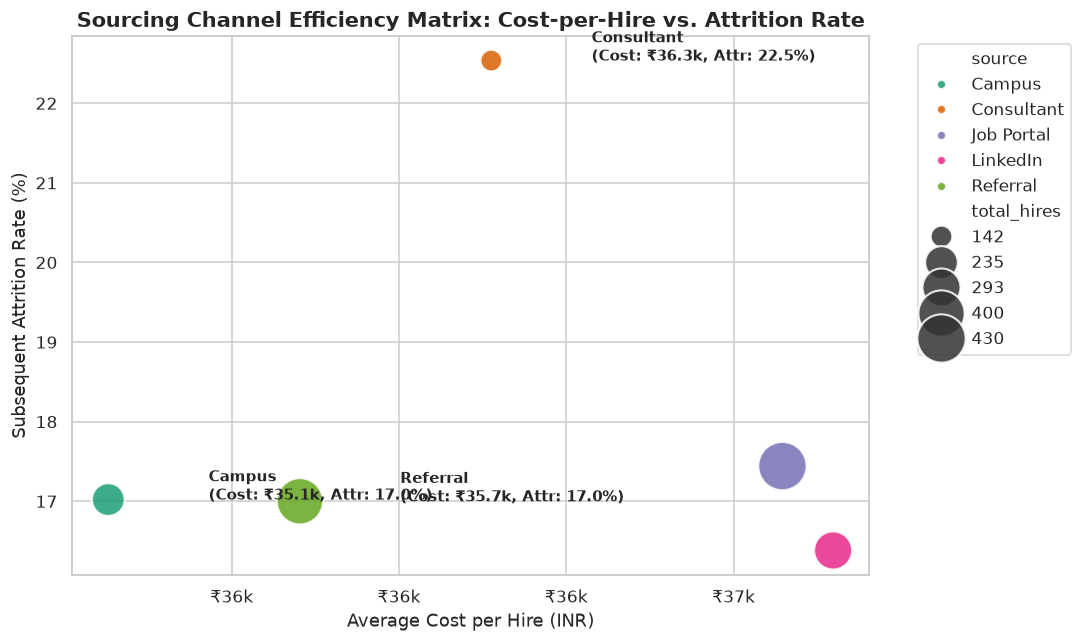

In [20]:
# Visualizing Sourcing Channel Efficiency and Quality Matrix
plt.figure(figsize=(10, 6))

scatter = sns.scatterplot(
    data=source_roi,
    x="avg_cost_inr",
    y="attrition_rate",
    size="total_hires",
    sizes=(200, 1000),
    hue="source",
    palette="Dark2",
    alpha=0.85
)

for _, row in source_roi.iterrows():
    plt.annotate(
        f"{row['source']}\n(Cost: ₹{row['avg_cost_inr']/1000:.1f}k, Attr: {row['attrition_rate']:.1f}%)",
        (row["avg_cost_inr"] + 300, row["attrition_rate"]),
        fontsize=10, fontweight="bold"
    )

plt.title("Sourcing Channel Efficiency Matrix: Cost-per-Hire vs. Attrition Rate", fontsize=14, fontweight="bold")
plt.xlabel("Average Cost per Hire (INR)", fontsize=12)
plt.ylabel("Subsequent Attrition Rate (%)", fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"₹{x*1e-3:,.0f}k"))
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Recruitment Channel ROI
1. **The Consultant Sourcing Inefficiency**:
   * *Data*: Hires brought in via external recruitment consultants carry the **highest attrition rate (22.54%)** and a high average cost-per-hire (~₹36,275).
   * *Comparison*: Direct sourcing via LinkedIn and Employee Referrals delivers lower attrition (**16.38%** and **17.00%**, respectively) and faster time-to-productivity.
2. **Talent Acquisition Budget Reallocation**:
   * Reduce external agency spend by **40%**.
   * Double the employee referral bonus program to incentivize internal teams to refer vetted candidates with strong cultural and technical fit.


---
## Chapter 9: Statutory Compliance, Governance & Workplace Risk

### Analytical Focus
Auditing statutory readiness: POSH, DPDP Act, Information Security courses, Background Verification (BGV) status, and employee grievances.


In [21]:
# Compliance Course Completion Rates
trainings = datasets["07_compliance_trainings"].copy()
comp_status = pd.crosstab(trainings["training_name"], trainings["status"], normalize="index") * 100

comp_records = datasets["08_compliance_employee_records"].copy()
bgv_status = comp_records["background_verification"].value_counts(normalize=True) * 100

comp_status


status,Completed,In Progress,Not Started,Overdue
training_name,,,,
Anti-Bribery,73.484236,7.922393,7.760711,10.832660
Code of Conduct,75.020210,8.245756,7.518189,9.215845
Data Privacy & DPDP Act,75.666936,7.679871,6.224737,10.428456
Fire & Safety,76.717866,7.679871,6.871463,8.730800
Information Security,74.535166,8.084074,7.356508,10.024252
POSH Awareness,76.071140,8.084074,5.982215,9.862571


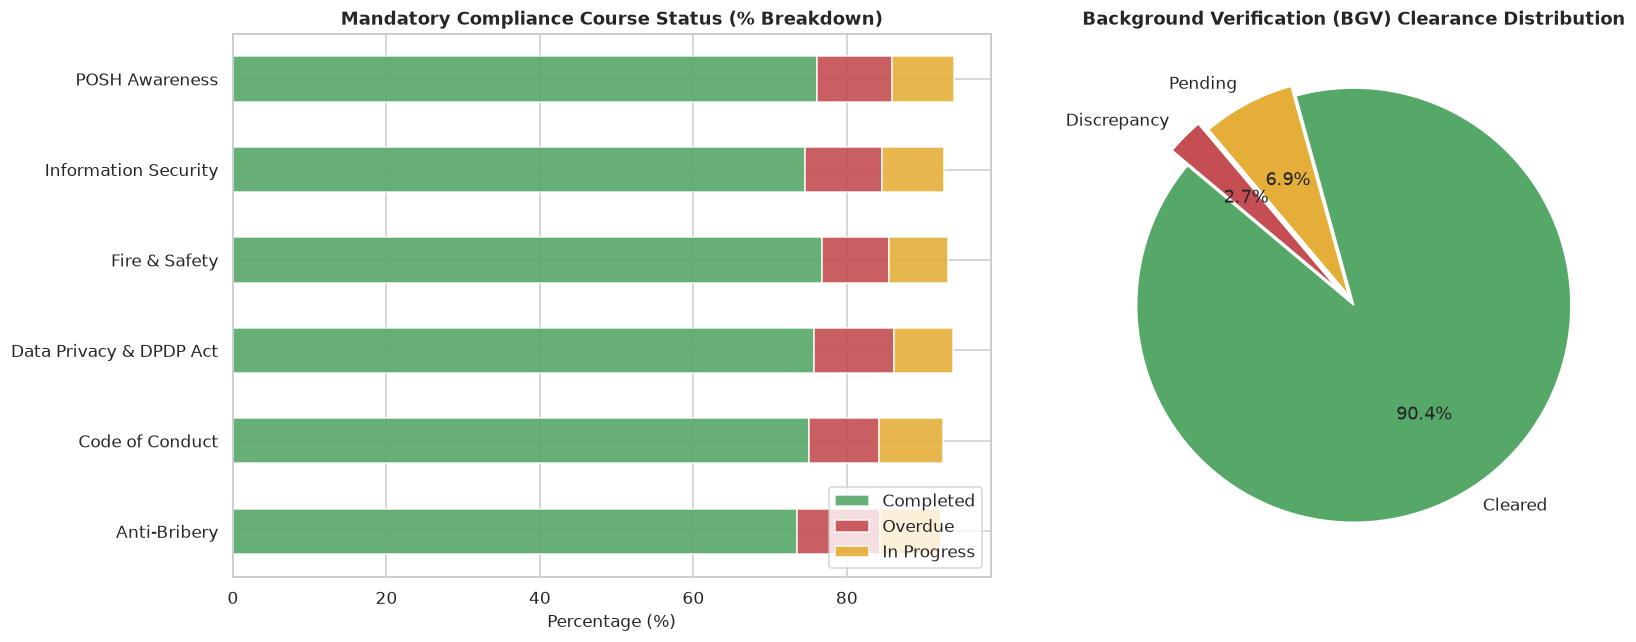

In [22]:
# Visualizing Compliance Completion & Statutory Governance Health
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Training Status across Mandatory Courses
comp_status[["Completed", "Overdue", "In Progress"]].plot(
    kind="barh", stacked=True, ax=axes[0], color=["#55A868", "#C44E52", "#E5AE38"], alpha=0.9
)
axes[0].set_title("Mandatory Compliance Course Status (% Breakdown)", fontweight="bold")
axes[0].set_xlabel("Percentage (%)")
axes[0].set_ylabel("")
axes[0].legend(loc="lower right")

# Panel 2: Background Verification (BGV) Status
bgv_status.plot(kind="pie", ax=axes[1], autopct='%1.1f%%', colors=["#55A868", "#E5AE38", "#C44E52"], startangle=140, explode=(0, 0.05, 0.1))
axes[1].set_title("Background Verification (BGV) Clearance Distribution", fontweight="bold")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### Strategic Insights & HR Prescriptions: Governance & Compliance
1. **Auditing Mandatory Certifications**:
   * *Status*: Overdue courses in high-stakes regulatory areas (such as DPDP Act and POSH Awareness) expose the enterprise to legal liability.
   * *Action*: Implement an automated Learning Management System (LMS) reminder cadence: automated notifications at 14, 7, and 1 day prior to due date, escalating to department heads upon overdue status.
2. **BGV Discrepancy Escalation**:
   * Enforce a strict **30-Day BGV Resolution SLA** from date of joining to eliminate operational and security vulnerabilities.


---
## Chapter 10: Executive Summary & Strategic HR Master Roadmap

### Consolidated People Analytics Scorecard

| Strategic Objective | Current Baseline Metric | Target Metric (12-Month) | Primary Strategic Initiative |
|---|---|---|---|
| **Overall Retention** | 17.53% Attrition | < 12.0% Attrition | Overtime capping + Early-warning absence intervention |
| **Sales & L1 Retention** | 25.12% (Sales), 25.63% (L1) | < 16.0% | Milestone retention bonuses & sales commission restructuring |
| **Employee Net Promoter (eNPS)** | 6.26 (Exited), 7.33 (Active) | > 8.5 Company-Wide | Frontline Manager Leadership Coaching & Recognition programs |
| **Recruitment Channel ROI** | 22.54% Consultant Attrition | < 15.0% | Reallocate 40% agency spend to Employee Referral program |
| **Early Warning Absenteeism** | 0.93 days/mo before exit | Proactive resolution | Automated HRIS alert on $\ge 2$ unplanned absences in 60 days |
| **Statutory Compliance** | Incomplete POSH/DPDP & BGV | 100% On-Time Completion | Automated LMS escalation + 30-day BGV onboarding cutoff |

---

### 30-60-90-180 Day Phased Action Plan for HR Leadership

```mermaid
gantt
    title People Strategy Execution Roadmap
    dateFormat  X
    axisFormat %d Days

    section Phase 1 (Days 1-30)
    Deploy HRIS Absence Alert Trigger       :active, p1_1, 0, 30
    Cap Mandatory Overtime in Sales/Ops     :p1_2, 10, 30
    Audit L3/L4 Gender Pay Equity           :p1_3, 15, 30

    section Phase 2 (Days 31-60)
    Launch Manager Leadership Academy       :p2_1, 30, 60
    Roll out 6-Month L1 Milestone Bonuses   :p2_2, 35, 60
    Overhaul Sourcing toward Referrals     :p2_3, 40, 60

    section Phase 3 (Days 61-90)
    Restructure Sales Compensation Model    :p3_1, 60, 90
    Automate Compliance LMS Escalations     :p3_2, 60, 85

    section Phase 4 (Days 91-180)
    Bi-Annual High-Performer Market Reviews :p4_1, 90, 180
    Annual Culture & eNPS Re-Survey         :p4_2, 150, 180
```

---
*Notebook compiled as part of the Enterprise People Analytics Masterclass.*
